# Fit thermo - rev01

|                     |     |
| ------------------- | --- |
| **Status**          | Draft, 2026-11-04. Steps 1–3 only: the spectra of the reaction experiments, their concentrations in time, the spectra of the 10-day experiments |
| **Source**          | Y. Alcaraz Galván; NMR data from experiments (N. Gogoi, 2023), raw `.jdf` files |
| **Scope**           | The spectra of the five reaction folders and of the three folders `… AFTER 10 DAYS`, measured only, drawn as in `06_fitting_thermo_rev01` §6 |
| **Builds on**       | `06_fitting_thermo_rev01` (its figures and reading of the spectra, from `05_fitting_rev08_(M1_steps)` §2) |

### Dependences

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# The repository holds the code, the results and the data: run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
CODE = REPO
if str(CODE) in sys.path:
    sys.path.remove(str(CODE))
sys.path.insert(0, str(CODE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.gridspec import GridSpec

import kinetics
from kinetics.data import calculate_molar_mass, load_lab_observables
from kinetics.data.lab_nmr import build_lab_nmr_inventory, calculate_area_shares, load_spectrum
from kinetics.data.observables import C_PHOSPHATE_WINDOWS_PPM, C_REGION_PPM, C_WINDOWS_PPM, P_WINDOWS_PPM, RT_MAX_C
from kinetics.fitting.reporting import P_REGION_PPM
from kinetics.fitting.residuals import SHARE_SPECIES
from kinetics.paths import lab_nmr_dir
from demo import fit_plots, style

assert Path(kinetics.__file__).parents[1] == CODE, f'kinetics was imported from {kinetics.__file__}, not from {CODE}'
style.apply_style()
pd.set_option('display.max_colwidth', None)

observables = load_lab_observables()
INVENTORY_ALL = build_lab_nmr_inventory(lab_nmr_dir())   # every .jdf of the raw data, copies included
print(f'Code: {CODE} · NMR data: {lab_nmr_dir()}')

Code: /home/yeray/projects/atom-to-reactor · NMR data: /home/yeray/data/nmr_raw_gogoi_2023


In [2]:
# The reading of the spectra of 06_fitting_thermo_rev01 (from 05_fitting_rev08 §2), measured only: the same windows, shares
# and figures, with no model drawn. Two changes: a spectrum is read with the windows of its tube (with or without phosphate),
# so a tube that is not in the observables (TMSOTMS + 2 % H2O, TMSOH + 2 % H2O) can be read too; and its time is the days
# since the first spectrum of its tube, from the acquisition times (no age before it)
SPECTRUM_VIEW = 'paper'
H1_REGION = (-0.35, 0.10)                     # ppm: the Si–CH3 region, where the phase of an FID is refined
# ²⁹Si, ppm as recorded (not referenced): HMDSO 7.8, TMSOH 14.2, TMS-EG 18.0, silyl on phosphate 21.6–23.0. Read by height
SI_WINDOWS = {'TMSOH': (13.0, 16.0), 'HMDSO': (6.5, 9.0), 'TMSOEG': (17.0, 20.0), 'P-silyl': (20.5, 25.0)}
SI_REGION = (-5.0, 35.0)
# ¹H, Si–CH3 region: one line per form of the silyl group (9 H each); TMSOH and HMDSO only 0.004–0.011 ppm apart, so one
# window takes all the free silyl
H1_WINDOWS = {'P-bound silyl': (-0.100, 0.060), 'free silyl': (-0.300, -0.150)}     # ppm (low, high)
H1_REFERENCES = {'TMSPA, fresh': (-0.041, 0), 'TMS-EG (paper)': (-0.215, 0), 'HMDSO (tube)': (-0.234, 1), 'TMSOH (paper)': (-0.245, 2)}   # ppm, label row
H1_SOLVENT = {'EC, CH₂ (s)': (4.224, 0), 'DEC, CH₂ (q)': (3.824, 0), 'H₂O (lock)': (3.288, 1), 'DMSO-d₅ (lock)': (2.462, 0),
              'DEC, CH₃ (t)': (0.944, 0), 'Si–CH₃': (-0.12, 0)}     # ppm, label row
# What the name or the title of a file says that its reading must keep in mind
FILE_NOTES = {'WW-NG-S1 TMSPa+H2O in EC-DEC_silicon-1-1.jdf': 'title WW-S12 (the ³¹P and ¹³C: WW-S1), recorded the evening before',
              '230515_5v%TMSPa+2v%TMSOH in EC_DEC_19F-1-2.jdf': 'named _19F, its header says ²⁹Si',
              'NG230525_5v% TMSPa+5v%TMSOH in EC_DEC_after 10d_Proton-1-1.jdf': 'titled 5v% TMSPa + 5v% TMSOH',
              'NG230525_5v% TMSPa+5v%TMSOH in EC_DEC_after 10d_inept_dec-1-1.jdf': 'titled 5v% TMSPa + 5v% TMSOH'}

# The tubes: 'first', the folders of its first spectra (the reaction experiment; the first spectrum of these is day 0 here);
# 'observables', its name in the observables (None: not a fitted tube). A file of a reaction folder is of the tube of the
# folder; a file of a folder '… AFTER 10 DAYS' is of the tube its title names (one folder holds two tubes)
TUBES = {'0.5 % H2O':         {'first': ['5% TMSPa + 0.5v% H2O in EC-DEC'], 'phosphate': True, 'observables': '0.5 % H2O'},
         '2 % H2O':           {'first': ['5% TMSPa + 2v% H2O in EC-DEC/Ramping Temperature',
                                         '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature'], 'phosphate': True, 'observables': '2 % H2O'},
         'TMSPa + TMSOH (A)': {'first': ['5v%TMSPa+2v%TMSOH in ECDEC'], 'phosphate': True, 'observables': 'TMSPa + TMSOH (A)'},
         'TMSOH + 2 % H2O':   {'first': ['5v% TMSOH+2v% H2O in ECDEC'], 'phosphate': False, 'observables': None},
         'TMSOTMS + 2 % H2O': {'first': ['5v%TMSOTMS+2v%H2O in ECDEC'], 'phosphate': False, 'observables': None},
         'TMSPa alone':       {'first': ['5v%TMSPa in EDEC'], 'phosphate': True, 'observables': 'TMSPa alone'}}
# Composition at mixing (M): the observables for a fitted tube; for the two others, the recipe (5 vol%) with the density of
# the liquid (g/mL, 25 °C: TMSOH 0.811 as in NB06 §6.0, HMDSO 0.764) and its molar mass
RECIPE_VOL_FRAC = {'TMSOH + 2 % H2O': {'TMSOH': 0.05}, 'TMSOTMS + 2 % H2O': {'HMDSO': 0.05}}
DENSITY_G_ML = {'TMSOH': 0.811, 'HMDSO': 0.764}


def mixing_c0(tube):
    name = TUBES[tube]['observables']
    if name:
        return observables['samples'][name]['c0_M']
    return {sp: f * 1000 * DENSITY_G_ML[sp] / calculate_molar_mass(sp) for sp, f in RECIPE_VOL_FRAC[tube].items()}


def abundant_concentration(rows, tube, nucleus):
    # The window with the largest share of one spectrum, and its concentration ± σ (mM). The windows of a nucleus count
    # together a conserved amount (³¹P: P atoms; ¹³C, ²⁹Si, ¹H: silyl groups), that of the mixing: Σ n × c0 over the
    # species of SHARE_SPECIES. A window of one species gives that species (share × total / n: HMDSO in molecules); a window
    # of several, their silyl groups (or P atoms). σ = √(σ_noise² + σ_baseline²) × total / n (²⁹Si, read by height: noise only)
    members, c0 = SHARE_SPECIES[nucleus], mixing_c0(tube)
    total = sum(n * c0.get(sp, 0.0) for window in rows['window'] for sp, n in members[window].items())
    top = rows.loc[rows['measured'].idxmax()]
    species = members[top['window']]
    n, name = (next(iter(species.values())), next(iter(species))) if len(species) == 1 else (1, f"{top['window']} ({'P' if nucleus == '31P' else 'silyl groups'})")
    sigma = np.hypot(top['sigma_noise'], top['sigma_baseline'])
    return name, 1000 * top['measured'] * total / n, 1000 * sigma * total / n


TUBE_OF_FOLDER = {folder: tube for tube, record in TUBES.items() for folder in record['first']}
NUCLEUS_ORDER = ['31P', '13C', '29Si', '1H', '19F']      # the files table: one block per nucleus, in this order
LINE_REGIONS = {'31P': (-32.0, 6.0), '13C': (-3.0, 2.5), '1H': (-0.35, 0.10), '29Si': (0.0, 35.0), '19F': (-300.0, 100.0)}   # ppm: where S/N is read (NB06)


def tube_of(folder, title):
    # The tube of a file: that of its folder (reaction folders), else the one its title names
    if folder in TUBE_OF_FOLDER:
        return TUBE_OF_FOLDER[folder]
    if 'TMSOTMS' in title:
        return 'TMSOTMS + 2 % H2O'
    if 'TMSOH+2v%H2O' in title:
        return 'TMSOH + 2 % H2O'
    return 'TMSPa + TMSOH (A)' if 'TMSPa+' in title.replace(' ', '') else 'TMSPa alone'


def axis_offset(tube, nucleus):
    # The shift of the axis of a tube for one nucleus (observables: ¹³C of the tubes with phosphate); 0 elsewhere
    name = TUBES[tube]['observables']
    return observables['samples'][name].get('more_nuclei', {}).get(nucleus, {}).get('axis_offset_ppm', 0.0) if name else 0.0


def list_folder(folders):
    # One row per .jdf of one or more folders, in the order acquired: its tube, its days since the first spectrum of the
    # tube, its header and a note. A file whose data are those of another one (same md5) is a copy: drawn and listed once
    folders = [folders] if isinstance(folders, str) else folders
    files = INVENTORY_ALL[INVENTORY_ALL['folder'].isin(folders)].sort_values(['acquired_at', 'file']).reset_index(drop=True)
    files['tube'] = [tube_of(folder, title) for folder, title in zip(files['folder'], files['title'])]
    first = {tube: INVENTORY_ALL.loc[INVENTORY_ALL['folder'].isin(TUBES[tube]['first']), 'acquired_at'].min() for tube in files['tube'].unique()}
    files['days'] = [(at - first[tube]).total_seconds() / 86400 for at, tube in zip(files['acquired_at'], files['tube'])]
    original = files.drop_duplicates('data_md5').set_index('data_md5')['file']
    files['copy of'] = [original[md5] if copy else None for md5, copy in zip(files['data_md5'], files.duplicated('data_md5'))]
    notes = []
    for _, r in files.iterrows():
        note = [FILE_NOTES.get(r['file'], '')]
        if r['temperature_C'] > RT_MAX_C:
            note.append(f"{r['temperature_C']:.0f} °C")
        if r['nucleus'] == '31P' and (r['noe'] == 'TRUE' or r['relaxation_delay_s'] < 5):
            note.append(('NOE on, ' if r['noe'] == 'TRUE' else '') + f"d1 {r['relaxation_delay_s']:g} s")
        if r['nucleus'] == '29Si':
            note.append('INEPT' if 'inept' in r['experiment'] else 'NOE on')
        if isinstance(r['copy of'], str):
            note.append(f"copy of {r['copy of']}")
        notes.append(', '.join(n for n in note if n))
    files['note'] = notes
    return files


def load_phased(path, window=None):
    return load_spectrum(path, window_ppm=window)


def signal_to_noise(path, nucleus, offset=0.0):
    # S/N = height of the tallest line over the baseline reference (median of the region) / (2 σ_noise), in the region where
    # the lines of the species are (LINE_REGIONS, moved by the axis offset of the tube). σ_noise: the spread (MAD) of the
    # differences between neighbouring points / √2, which a sloping baseline does not raise (NB06 peak_to_noise)
    low, high = LINE_REGIONS[nucleus]
    ppm, intensity = load_phased(path, (low + offset, high + offset) if nucleus != '1H' or h1_phase_window(path) else None)
    y = intensity[(ppm >= low + offset) & (ppm <= high + offset)]
    step = np.diff(y)
    sigma = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
    return float((y.max() - np.median(y)) / (2 * sigma))


def h1_phase_window(path):
    # The ¹H region whose phase is refined: that of Si–CH3 for an FID; none for a spectrum processed on the spectrometer
    return H1_REGION if INVENTORY_ALL.set_index('path').loc[path, 'data_kind'] == 'FID' else None


def calculate_height_shares(ppm, intensity, windows_ppm, *, region_ppm, pad_ppm=0.5):
    # ²⁹Si: the share of the summed height (its lines are one or two points wide on a rolling baseline). Each height is the
    # tallest point of the window over the median of two pads beside it; an empty window reads the top of its noise, about 4 σ
    inside = (ppm >= region_ppm[0]) & (ppm <= region_ppm[1])
    x, y = ppm[inside], intensity[inside]
    step = np.diff(y)
    noise = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
    heights = {}
    for name, (low, high) in windows_ppm.items():
        pads = ((x >= low - pad_ppm) & (x < low)) | ((x > high) & (x <= high + pad_ppm))
        heights[name] = float(y[(x >= low) & (x <= high)].max() - np.median(y[pads]))
    total = sum(heights.values())
    shares = pd.DataFrame({'share': {name: h / total for name, h in heights.items()}, 'height': heights})
    shares['sigma'] = [noise * np.sqrt((1.0 - s) ** 2 + s ** 2 * (len(heights) - 1)) / total for s in shares['share']]
    return shares


def reading_of(nucleus, tube):
    # Windows, region and options of the shares of a spectrum, as in NB06; a tube without phosphate has no window for the
    # silyl on phosphate
    offset, phosphate = axis_offset(tube, nucleus), TUBES[tube]['phosphate']
    if nucleus == '31P':
        return P_WINDOWS_PPM, P_REGION_PPM, {}
    if nucleus == '13C':
        windows = C_PHOSPHATE_WINDOWS_PPM if phosphate else C_WINDOWS_PPM
        return ({window: (low + offset, high + offset) for window, (low, high) in windows.items()},
                (C_REGION_PPM[0] + offset, C_REGION_PPM[1] + offset), {})
    if nucleus == '29Si':
        return {window: limits for window, limits in SI_WINDOWS.items() if window != 'P-silyl' or phosphate}, SI_REGION, {}
    if nucleus == '1H':
        return ({window: limits for window, limits in H1_WINDOWS.items() if window != 'P-bound silyl' or phosphate},
                (-1.0, 0.6), {'baseline_pad_ppm': 0.1, 'exclusion_pad_ppm': 0.05})
    return None


def read_spectrum(path, nucleus, tube):
    # Shares of one spectrum and, but for ¹H, the spectrum as NB06 draws it: cut to the region, a cubic baseline removed
    # outside the windows, divided by the summed area of the windows
    windows, region, options = reading_of(nucleus, tube)
    ppm, intensity = load_phased(path, h1_phase_window(path) if nucleus == '1H' else region)
    if nucleus == '29Si':
        shares = calculate_height_shares(ppm, intensity, windows, region_ppm=region)
    else:
        shares = calculate_area_shares(ppm, intensity, windows, region_ppm=region, **options)
    if nucleus == '1H':
        return shares, None
    inside = (ppm >= region[0]) & (ppm <= region[1])
    x, y = ppm[inside], intensity[inside]
    free = np.ones(len(x), dtype=bool)
    for low, high in windows.values():
        free &= ~((x >= low - 0.3) & (x <= high + 0.3))
    y = y - np.polyval(np.polyfit(x[free], y[free], 3), x)
    area = sum(float(y[(x >= low) & (x <= high)].sum() * abs(x[1] - x[0])) for low, high in windows.values())
    if nucleus == '29Si':                             # read by height: the area its lines would have at the width of the tallest one
        top = int(np.argmax(y))
        area = float(shares['height'].sum()) * 1.0645 * abs(x[1] - x[0]) * max(1, int(np.sum(y[max(0, top - 20):top + 21] > 0.5 * y[top])))
    return shares, {'ppm': x, 'intensity': y / area, 'area': area, 'windows_ppm': dict(windows), 'axis_offset_ppm': axis_offset(tube, nucleus)}


def label_row(row):
    # The label of a spectrum in the figures: days since the first spectrum of its tube, and what sets it apart
    return f"{row['days']:.1f} d" + (f", {row['note']}" if row['note'] else '')      # the note holds the temperature of a hot spectrum


def add_h1_rows(fig, axes, h1, title=None):
    # One row per ¹H spectrum: the whole spectrum, then its Si–CH3 region with the measured shares, as in NB06 (no simulated
    # line). Under the axes of fig when fig is given; otherwise a figure of its own
    files = list(h1.drop_duplicates('path').sort_values('spectrum')['path'])      # in the order acquired
    if fig is None:
        fig = plt.figure(figsize=(9.6, 0.9 + 2.6 * len(files)), layout='constrained')
        grid = GridSpec(len(files), 1, figure=fig)
        rows = [grid[k] for k in range(len(files))]
        fig.suptitle(title, x=0.01, ha='left', fontsize=11)
    else:
        width, height = fig.get_size_inches()
        fig.set_size_inches(width, height + 2.6 * len(files))
        grid = GridSpec(1 + len(files), 1, figure=fig, height_ratios=[height - 0.9] + [2.6] * len(files))
        for k, ax in enumerate(axes.flat):
            ax.set_subplotspec(grid[0].subgridspec(len(axes.flat), 1)[k])
        rows = [grid[1 + k] for k in range(len(files))]
    for k, (file, spec) in enumerate(zip(files, rows)):
        seen = h1[h1['path'] == file].set_index('window')
        whole, zoom = (fig.add_subplot(s) for s in spec.subgridspec(1, 2, width_ratios=[1.6, 1]))
        ppm, intensity = load_phased(file)          # the whole spectrum with its own phase; the Si–CH3 region with the phase of that region
        y = intensity / intensity.max()
        region = (ppm <= 4.7) & (ppm >= -0.45)
        whole.plot(ppm[region], y[region], color=style.SERIES[7], lw=0.7)
        for name, (position, row) in H1_SOLVENT.items():
            near = np.abs(ppm - position) < 0.05
            whole.text(position, y[near].max() + 0.04 + 0.12 * row, name, ha='center', va='bottom', fontsize=7.5, color=fit_plots.INK)
        whole.axvspan(-0.30, 0.06, color=fit_plots.GRID, alpha=0.45, lw=0)
        whole.set_xlim(4.7, -0.45); whole.set_ylim(-0.05, 1.25); whole.set_yticks([]); whole.grid(False)
        whole.set_xlabel('δ(¹H) (ppm)')
        whole.set_ylabel(f"{seen.iloc[0]['tube']}\n{label_row(seen.iloc[0])}, ¹H", rotation=0, ha='right', va='center', fontsize=8.5, color=fit_plots.INK)
        ppm, intensity = load_phased(file, h1_phase_window(file))
        region = (ppm <= 0.10) & (ppm >= -0.35)
        y = intensity[region] / intensity[region].max()
        for name, (low, high) in H1_WINDOWS.items():
            if name not in seen.index:                # the window of the silyl on phosphate, in a tube without phosphate
                continue
            zoom.axvspan(low, high, color=fit_plots.GRID, alpha=0.45, lw=0)
            zoom.text(0.5 * (low + high), 1.5, name, ha='center', va='bottom', fontsize=8.5, color=fit_plots.INK)
            zoom.text(0.5 * (low + high), 1.3, f"{seen.loc[name, 'measured']:.2f}", ha='center', va='center', fontsize=7.5, color=fit_plots.INK_SOFT)
        zoom.plot(ppm[region], y, color=style.SERIES[7], lw=0.7, zorder=3)
        for name, (position, row) in H1_REFERENCES.items():
            zoom.axvline(position, ymax=0.75, color=fit_plots.INK_SOFT, ls=':', lw=0.8)
            zoom.text(position, -0.1 - 0.15 * row, f'{name} {position:+.3f}', ha='center', va='top', fontsize=6.5, color=fit_plots.INK_SOFT)
        zoom.set_xlim(0.10, -0.35); zoom.set_ylim(-0.55, 1.75); zoom.set_yticks([]); zoom.grid(False)
        zoom.set_xlabel('δ(¹H) (ppm), Si–CH₃')
        if k == 0:
            whole.text(0.55, 0.95, 'Spectrum: lab NMR data.\nLines identified with Gogoi et al., Fig. 5b\n(HMDSO from the HMDSO + H₂O tube).',
                       transform=whole.transAxes, ha='center', va='top', fontsize=7.5, color=fit_plots.INK_SOFT)
    return fig


def tabulate_folder(files):
    # Every spectrum of a folder read (copies once), one row per window, in the columns plot_spectra_comparison reads
    # ('predicted' NaN: nothing is simulated here); and the spectra read for the figures (¹H: drawn by add_h1_rows)
    rows, spectra = [], {}
    for number, (_, r) in enumerate(files[files['copy of'].isna()].iterrows()):
        if reading_of(r['nucleus'], r['tube']) is None:
            continue
        measured, spectrum = read_spectrum(r['path'], r['nucleus'], r['tube'])
        if spectrum is not None:
            spectra[(r['tube'], r['nucleus'], number)] = spectrum
        rows += [{'sample': r['tube'], 'tube': r['tube'], 'nucleus': r['nucleus'], 'spectrum': number, 't_h': 24 * r['days'],
                  'days': r['days'], 'T_C': r['temperature_C'], 'window': window, 'measured': m['share'], 'sigma_nmr': m['sigma'],
                  'sigma_noise': m.get('sigma_noise', m['sigma']), 'sigma_baseline': m.get('sigma_baseline', 0.0),
                  'predicted': np.nan, 'note': r['note'], 'file': r['file'], 'path': r['path']} for window, m in measured.iterrows()]
    return pd.DataFrame(rows), spectra


def tabulate_files(files, shares):
    # The files table: one block per nucleus (NUCLEUS_ORDER), each in the order acquired; copies once. The species with the
    # largest share and its concentration ± σ (abundant_concentration)
    table = files[files['copy of'].isna()].copy()
    read = {path: abundant_concentration(rows, rows['tube'].iloc[0], rows['nucleus'].iloc[0]) for path, rows in shares.groupby('path')}
    table['species'] = [read[path][0] if path in read else '' for path in table['path']]
    table['conc. (mM)'] = [read[path][1] if path in read else np.nan for path in table['path']]
    table['σ (mM)'] = [read[path][2] if path in read else np.nan for path in table['path']]
    table['σ (%)'] = 100 * table['σ (mM)'] / table['conc. (mM)']
    table['S/N'] = [signal_to_noise(r['path'], r['nucleus'], axis_offset(r['tube'], r['nucleus'])) for _, r in table.iterrows()]
    table['time per scan (s)'] = 60 * table['duration_min'] / table['scans']
    table['order'] = table['nucleus'].map({n: k for k, n in enumerate(NUCLEUS_ORDER)})
    table = table.sort_values(['order', 'acquired_at'], kind='stable')
    return table.rename(columns={'acquired_at': 'acquired', 'scans': 'scans', 'relaxation_delay_s': 'delay d1 (s)', 'temperature_C': 'T (°C)'})[
        ['nucleus', 'acquired', 'species', 'conc. (mM)', 'σ (mM)', 'σ (%)', 'S/N', 'scans', 'time per scan (s)', 'delay d1 (s)', 'T (°C)']]


def show_folder(folders, when=''):
    # One or more folders, nucleus by nucleus (NUCLEUS_ORDER), each under its letter: the figure of its spectra (every tube
    # of the folder, in the order acquired; ¹H as the rows of NB06), then its tables: the files, and the measured shares
    files = list_folder(folders)
    shares, spectra = tabulate_folder(files)
    table = tabulate_files(files, shares)
    for letter, nucleus in zip('ABCDEFG', [n for n in NUCLEUS_ORDER if n in set(table['nucleus'])]):
        label = fit_plots.NUCLEUS_LABELS.get(nucleus, nucleus)
        display(Markdown(f'#### {letter}. {label}'))
        mine = shares[shares['nucleus'] == nucleus]
        title = f"{', '.join(mine['tube'].unique())}, {label}: measured{when}"
        if nucleus == '1H' and len(mine):
            fig = add_h1_rows(None, None, mine, title=title)
            display(fig)
            plt.close(fig)
        elif len(mine):
            seen = mine.drop_duplicates('spectrum').sort_values('spectrum')
            axes = fit_plots.plot_spectra_comparison(spectra, mine, nucleus=nucleus,
                                                     rows=[(r['tube'], int(r['spectrum']), label_row(r)) for _, r in seen.iterrows()],
                                                     fit_label='Simulated: none (measured only)', title=title, view=SPECTRUM_VIEW)
            display(axes.flat[0].figure)
            plt.close(axes.flat[0].figure)
        display(table[table['nucleus'] == nucleus].style.hide(axis='index')
                .format({'conc. (mM)': '{:.1f}', 'σ (mM)': '{:.1f}', 'σ (%)': '{:.1f}', 'S/N': '{:.0f}', 'time per scan (s)': '{:.2f}', 'delay d1 (s)': '{:g}', 'T (°C)': '{:.1f}'}))
        if len(mine):
            display(mine.assign(share=mine['measured'], σ=mine['sigma_nmr'])
                    .pivot_table(index=['tube', 'days'], columns='window', values=['share', 'σ'], sort=False)
                    .style.format('{:.3f}', na_rep='').format_index('{:.2f}', level=1))

---
## 1. Reaction experiments

The five tubes in which a reaction was followed from mixing: TMSPa with 0.5 % or 2 % H₂O or with 2 % TMSOH, and TMSOH or TMSOTMS (HMDSO) with 2 % H₂O. Nothing is simulated: each figure shows the measured spectrum, the window of each species (grey) and its measured share of the area of the windows (²⁹Si: of the heights). Time: days since the first spectrum of the same tube.

- **Per nucleus (A, B, …):** the figure of its spectra, as in `06_fitting_thermo_rev01` §6 (¹H: the whole spectrum and its Si–CH₃ region), every tube of the folder in the order acquired; then its tables: the files (the species with the largest share, its concentration ± σ, signal to noise, scans, time per scan, delay d1, temperature) and the measured share of each window ± its noise (σ).

S/N = height of the tallest line over the baseline (median of the region) / (2 σ_noise), read in the region of the species lines: ³¹P −32 to 6 ppm, ¹³C −3 to 2.5 ppm (Si–CH₃), ²⁹Si 0 to 35 ppm, ¹H −0.35 to 0.10 ppm (Si–CH₃). Time per scan = duration of the acquisition / scans (it holds the delay d1).

Conc. = share × the amount all the windows of the nucleus count together at mixing (³¹P: P atoms; ¹³C, ²⁹Si, ¹H: silyl groups), divided by the groups per molecule for a window of one species (HMDSO: 2); a window of several species (silyl on phosphate, P-bound or free silyl, TMSOEG) is given in silyl groups. σ = √(σ_noise² + σ_baseline²) on the same scale (²⁹Si, read by height: noise only); σ (%) = σ / conc. At mixing: the observables for the fitted tubes; for TMSOH + 2 % H₂O and TMSOTMS + 2 % H₂O, 5 vol% (TMSOH 450 mM, HMDSO 235 mM).

### 1.1 `5% TMSPa + 0.5v% H2O`

`0.5 % H2O`. The ²⁹Si (title WW-S12) was recorded the evening before the ³¹P and ¹³C (WW-S1): it is the first spectrum of the tube, day 0.

#### A. ³¹P

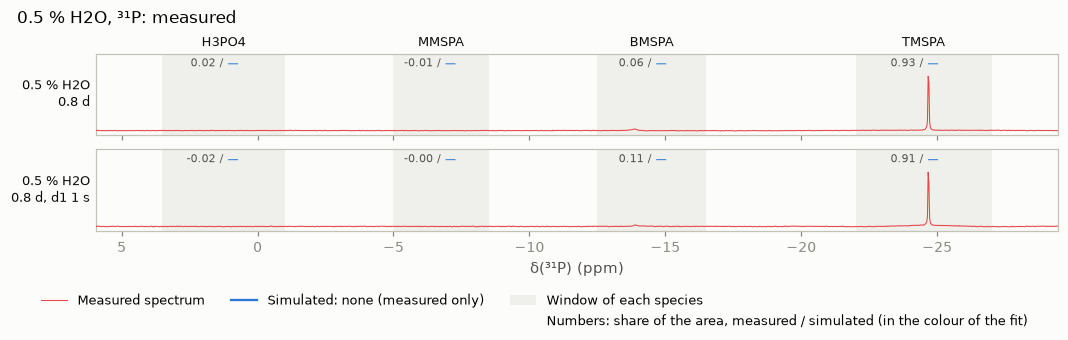

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2022-04-22 12:58:50,TMSPA,139.0,2.9,2.1,233,16,5.69,5,22.3
31P,2022-04-22 13:01:19,TMSPA,135.9,7.2,5.3,163,16,1.56,1,22.3


#### B. ¹³C

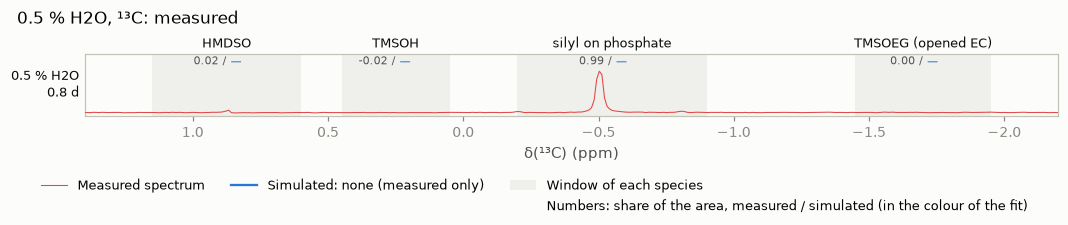

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
13C,2022-04-22 13:03:20,P-silyl (silyl groups),445.9,5.7,1.3,234,256,3.10,2,22.3


#### C. ²⁹Si

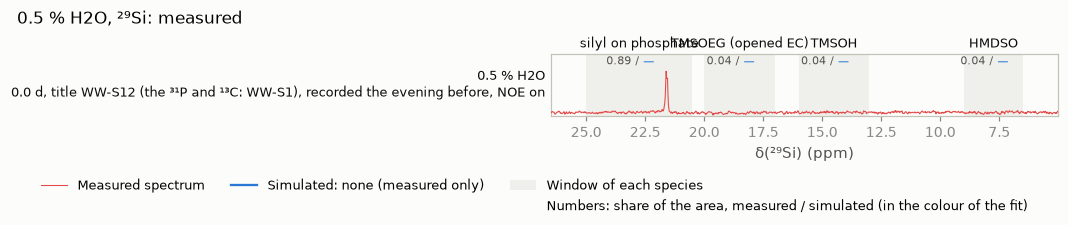

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2022-04-21 18:07:01,P-silyl (silyl groups),398.2,7.2,1.8,44,6000,5.66,5,21.8


In [3]:
show_folder('5% TMSPa + 0.5v% H2O in EC-DEC')

### 1.2 `5% TMSPa + 2v% H2O`

`2 % H2O`: its two folders together, `Ramping Temperature` (spectra at 30–80 °C) and `After Ramping Temperature` (back at room temperature after each heating).

#### A. ³¹P

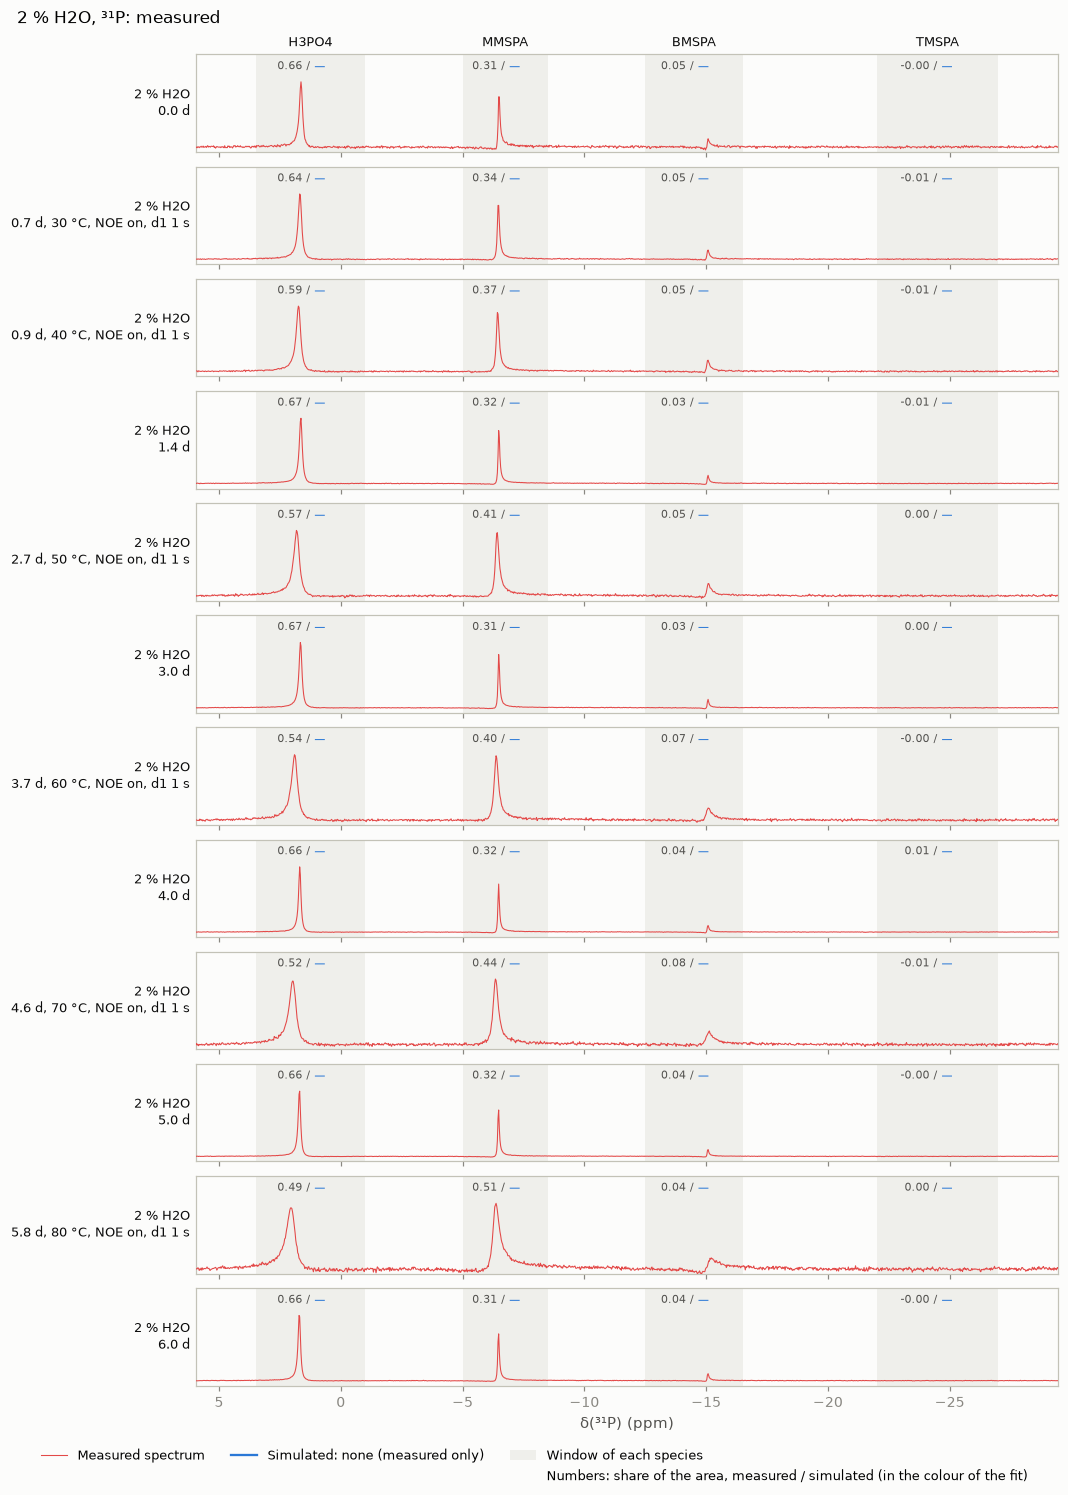

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2022-06-22 18:09:08,H3PO4,99.3,1.8,1.8,55,16,5.69,5,22.5
31P,2022-06-23 10:41:15,H3PO4,95.4,0.7,0.7,127,256,1.52,1,30.0
31P,2022-06-23 15:33:20,H3PO4,88.8,1.1,1.3,86,256,1.54,1,40.0
31P,2022-06-24 03:09:41,H3PO4,99.6,1.0,1.1,229,256,5.26,5,22.3
31P,2022-06-25 11:33:27,H3PO4,85.3,2.7,3.2,63,256,1.52,1,50.0
31P,2022-06-25 18:09:13,H3PO4,99.6,1.6,1.6,242,256,5.25,5,22.4
31P,2022-06-26 09:47:56,H3PO4,80.9,1.2,1.5,54,256,1.53,1,60.0
31P,2022-06-26 18:09:29,H3PO4,98.1,2.1,2.1,275,256,5.25,5,22.5
31P,2022-06-27 08:08:41,H3PO4,77.1,4.8,6.3,42,256,1.53,1,70.0
31P,2022-06-27 18:09:35,H3PO4,98.3,0.9,1.0,286,256,5.25,5,22.8


#### B. ¹³C

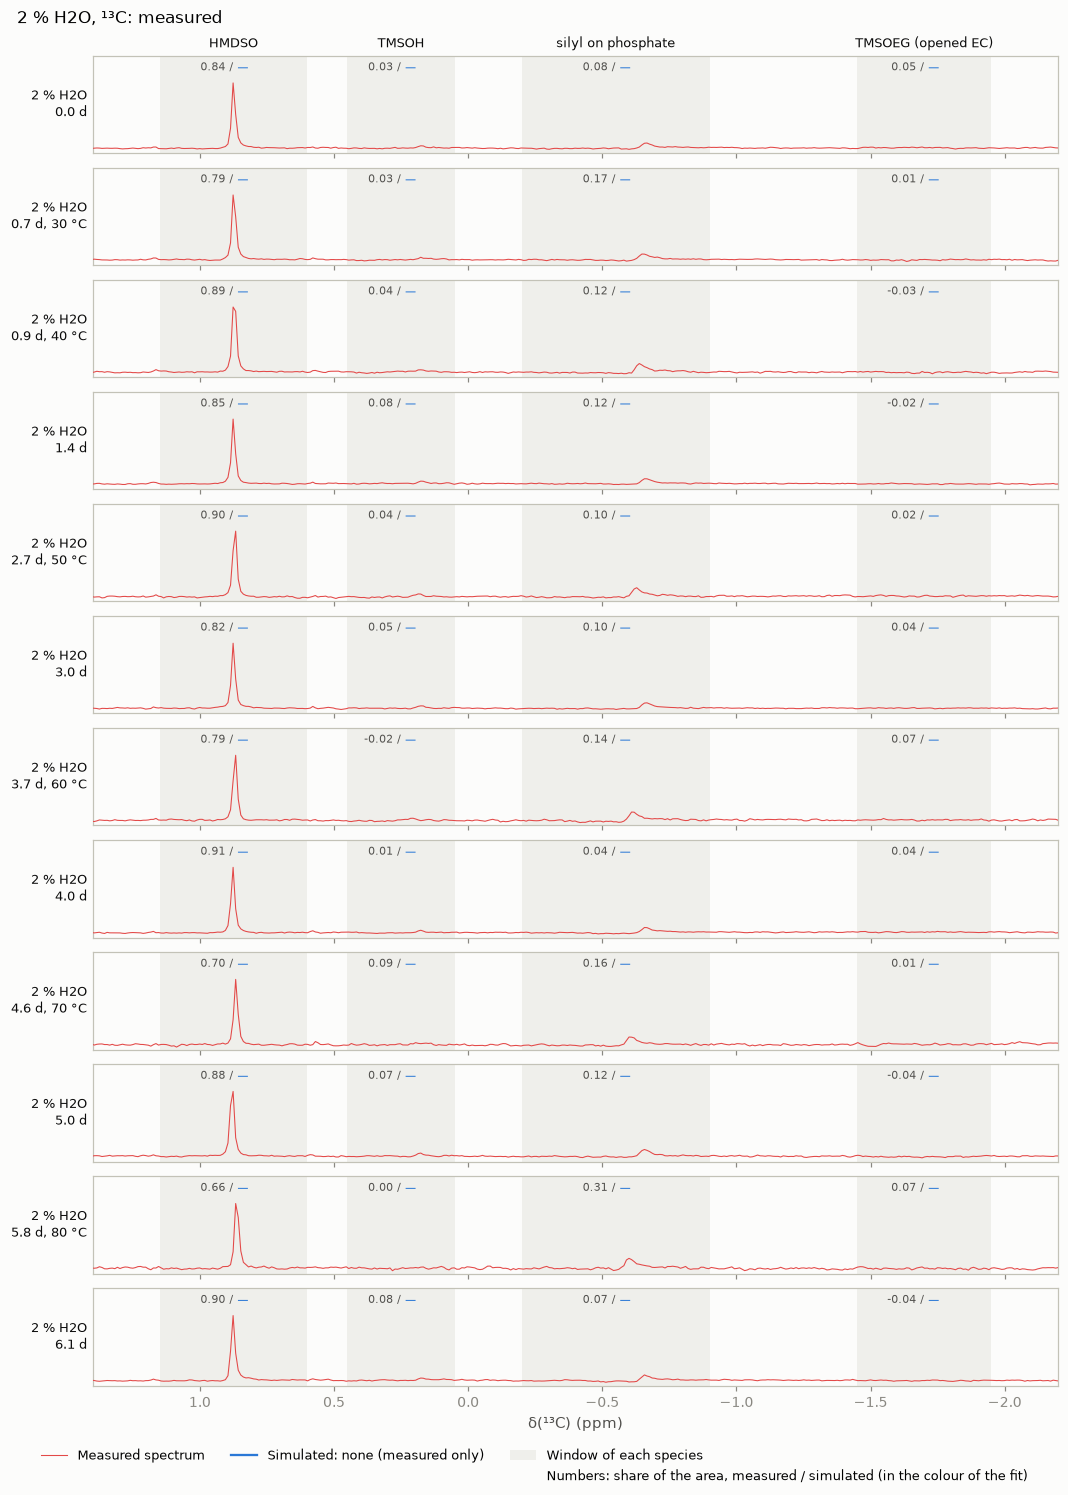

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
13C,2022-06-22 18:12:20,HMDSO,189.1,5.7,3.0,127,50,3.30,2,22.4
13C,2022-06-23 10:35:55,HMDSO,177.5,23.0,13.0,113,64,3.27,2,30.0
13C,2022-06-23 15:28:03,HMDSO,199.4,15.6,7.8,89,64,3.25,2,40.0
13C,2022-06-24 03:33:44,HMDSO,190.1,34.7,18.2,127,64,3.25,2,22.3
13C,2022-06-25 11:28:04,HMDSO,201.1,37.8,18.8,82,64,3.25,2,50.0
13C,2022-06-25 18:33:17,HMDSO,184.2,5.0,2.7,126,64,3.25,2,22.4
13C,2022-06-26 09:42:15,HMDSO,177.3,27.6,15.6,88,64,3.25,2,60.0
13C,2022-06-26 18:34:36,HMDSO,203.4,19.2,9.4,130,64,3.25,2,22.5
13C,2022-06-27 08:03:17,HMDSO,157.6,36.8,23.4,67,64,3.25,2,70.0
13C,2022-06-27 18:33:35,HMDSO,196.2,19.9,10.1,99,64,3.25,2,22.8


#### C. ²⁹Si

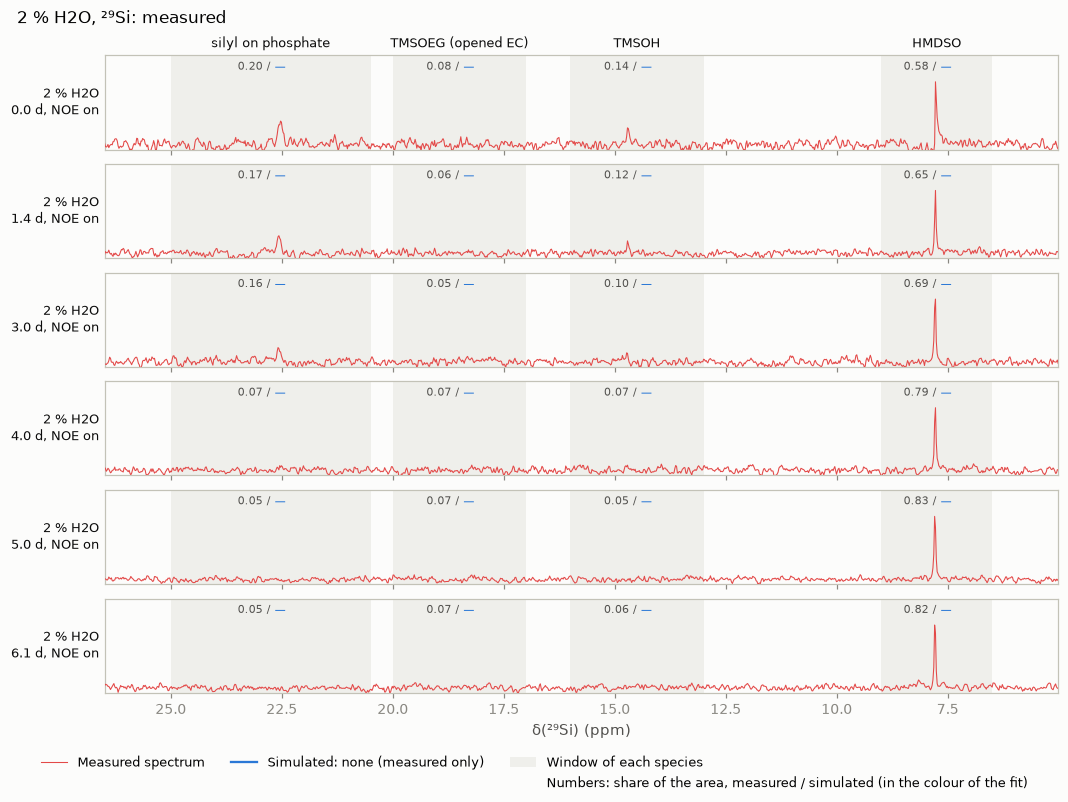

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2022-06-22 18:16:40,HMDSO,129.0,4.0,3.1,18,6000,5.66,5,22.3
29Si,2022-06-24 03:38:40,HMDSO,145.1,3.6,2.5,24,6000,5.66,5,22.3
29Si,2022-06-25 18:38:15,HMDSO,155.0,4.3,2.8,22,6000,5.66,5,22.3
29Si,2022-06-26 18:39:30,HMDSO,177.1,5.1,2.9,24,6000,5.66,5,22.5
29Si,2022-06-27 18:38:34,HMDSO,185.4,4.1,2.2,32,6000,5.66,5,22.5
29Si,2022-06-28 19:39:09,HMDSO,184.5,4.8,2.6,28,6000,5.66,5,22.6


#### D. ¹H

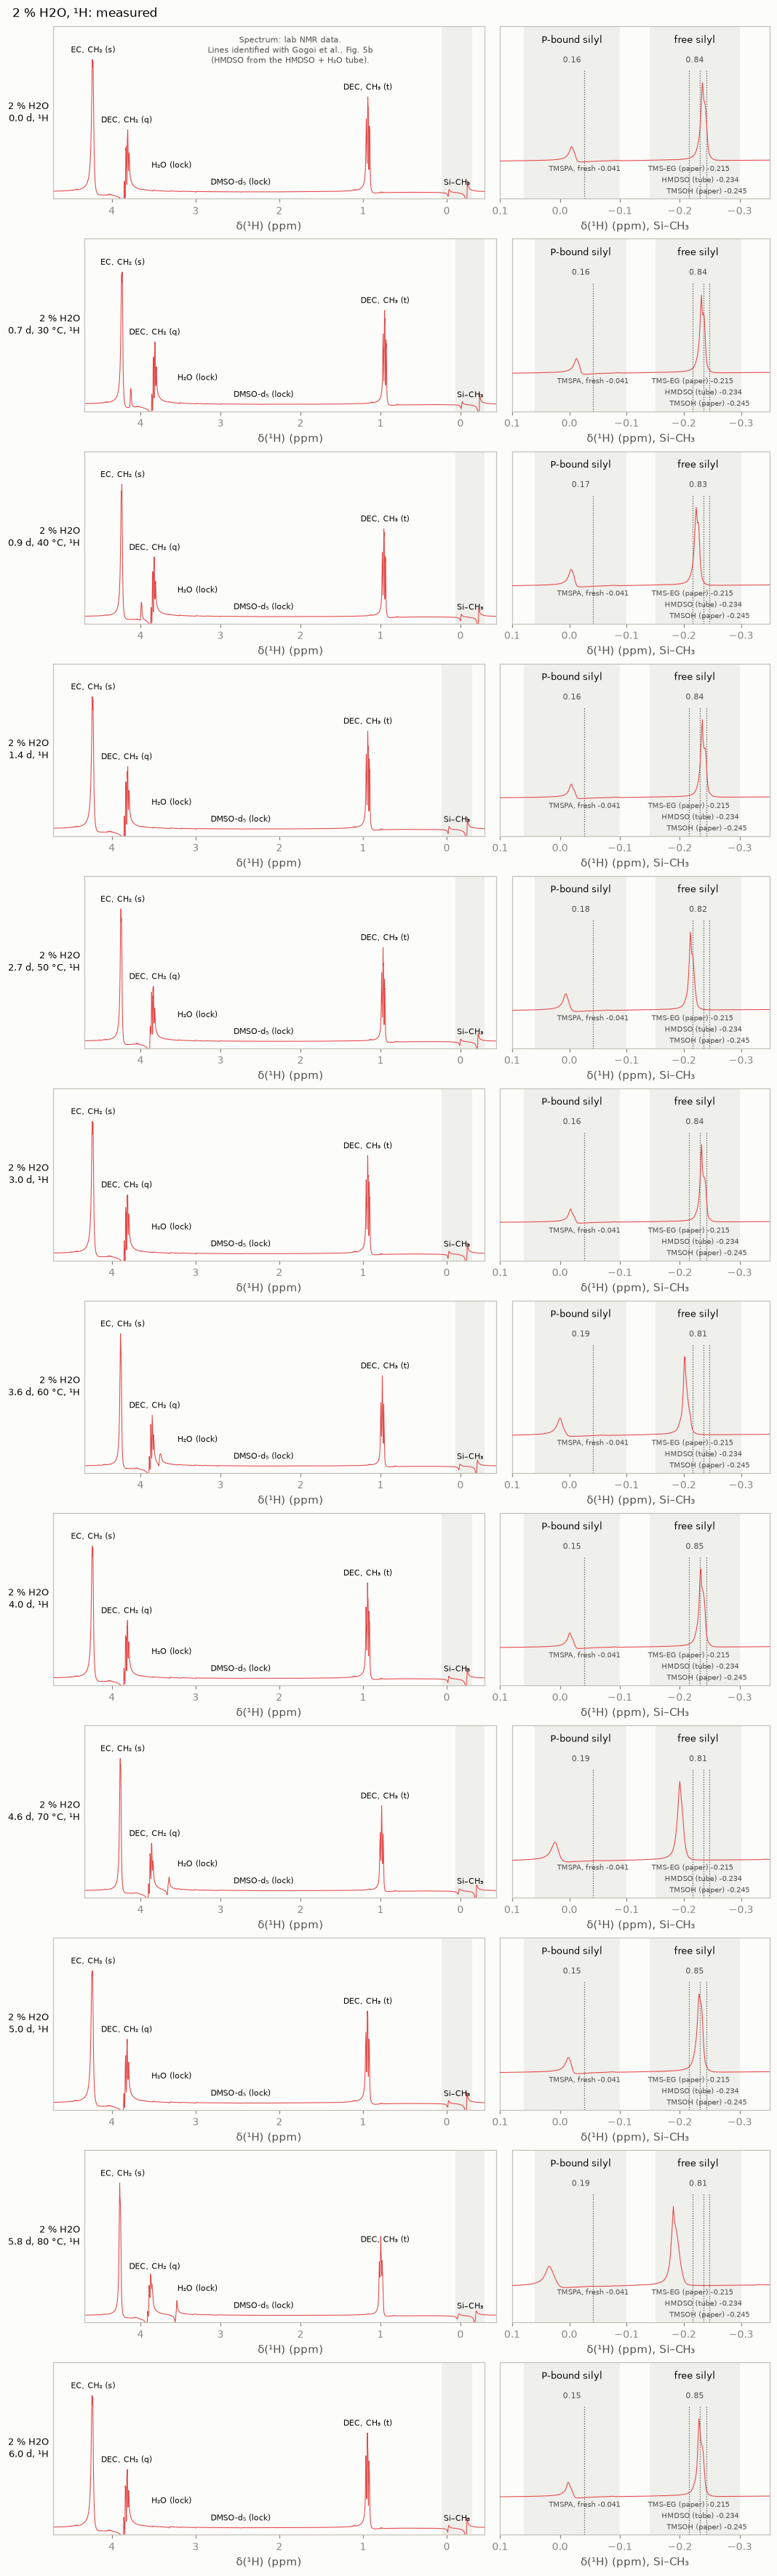

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2022-06-22 18:04:30,free silyl (silyl groups),378.0,21.4,5.7,3672,50,3.26,1,22.5
1H,2022-06-23 10:30:25,free silyl (silyl groups),375.3,20.5,5.5,3529,64,3.25,1,30.0
1H,2022-06-23 15:22:38,free silyl (silyl groups),371.8,20.1,5.4,3230,64,3.27,1,40.0
1H,2022-06-24 03:04:20,free silyl (silyl groups),377.6,21.8,5.8,4178,64,3.25,1,22.4
1H,2022-06-25 11:22:23,free silyl (silyl groups),367.8,19.9,5.4,3205,64,3.25,1,50.0
1H,2022-06-25 18:03:49,free silyl (silyl groups),377.9,21.5,5.7,4425,64,3.27,1,22.5
1H,2022-06-26 09:36:07,free silyl (silyl groups),364.6,21.8,6.0,2806,64,3.27,1,60.0
1H,2022-06-26 18:04:16,free silyl (silyl groups),379.2,21.4,5.7,3614,64,3.25,1,22.6
1H,2022-06-27 07:57:47,free silyl (silyl groups),362.9,26.7,7.4,2237,64,3.27,1,70.0
1H,2022-06-27 18:04:20,free silyl (silyl groups),381.8,21.0,5.5,3146,64,3.25,1,22.9


In [4]:
show_folder(['5% TMSPa + 2v% H2O in EC-DEC/Ramping Temperature', '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature'])

### 1.3 `5v%TMSPa + 2v%TMSOH`

`TMSPa + TMSOH (A)`. The file named `_19F` is a ²⁹Si spectrum (its header).

#### A. ³¹P

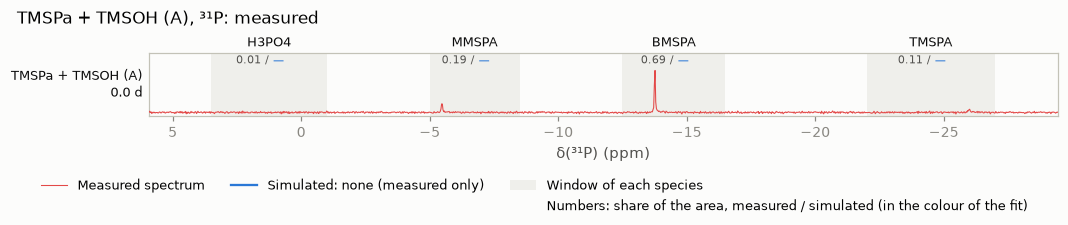

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2023-05-15 17:06:48,BMSPA,102.7,8.4,8.2,38,16,5.69,5,21.7


#### B. ²⁹Si

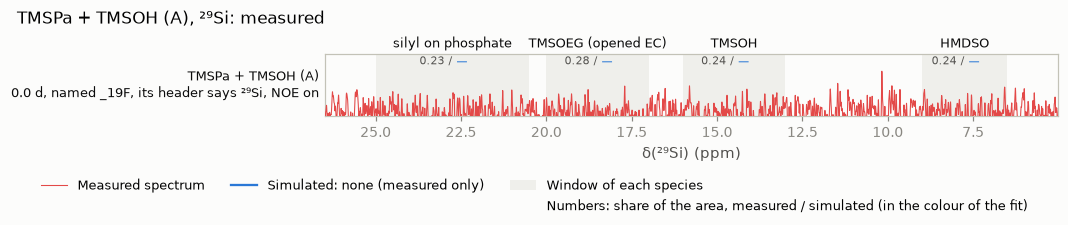

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-15 17:10:08,TMSOEG (silyl groups),175.1,28.4,16.2,3,256,10.34,5,21.6


#### C. ¹H

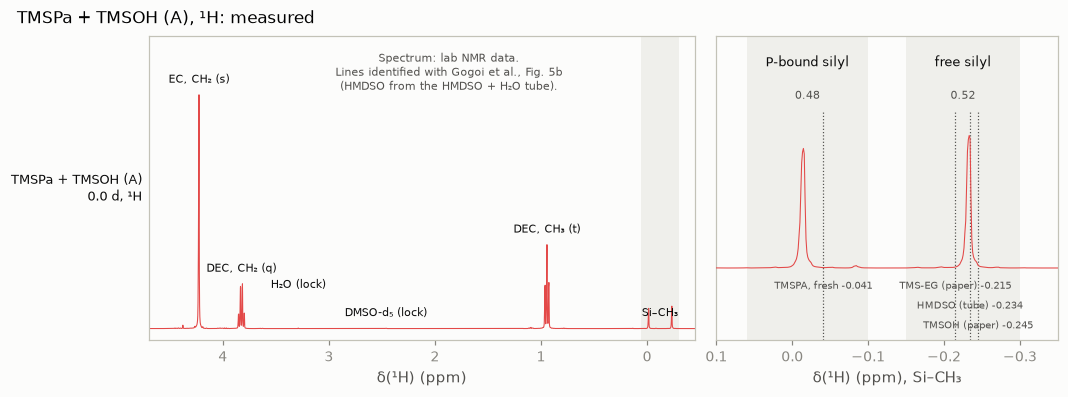

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-15 17:03:07,free silyl (silyl groups),324.4,0.5,0.1,2671,16,7.81,5,21.7


In [5]:
show_folder('5v%TMSPa+2v%TMSOH in ECDEC')

### 1.4 `5v% TMSOH + 2v% H2O`

Not a fitted tube; no phosphate, so ¹H has only the window of the free silyl.

#### A. ²⁹Si

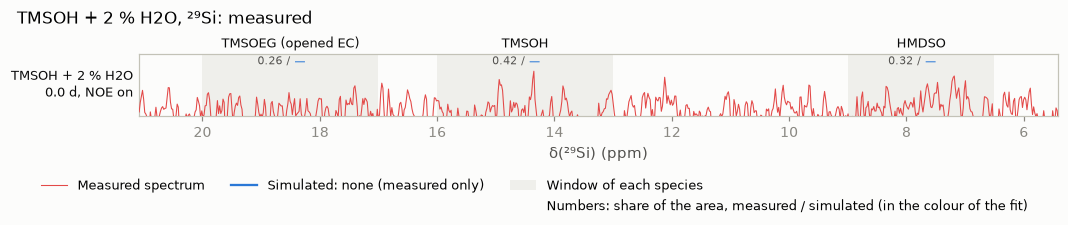

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-17 17:10:12,TMSOH,188.5,22.9,12.2,3,6000,5.66,5,21.9


#### B. ¹H

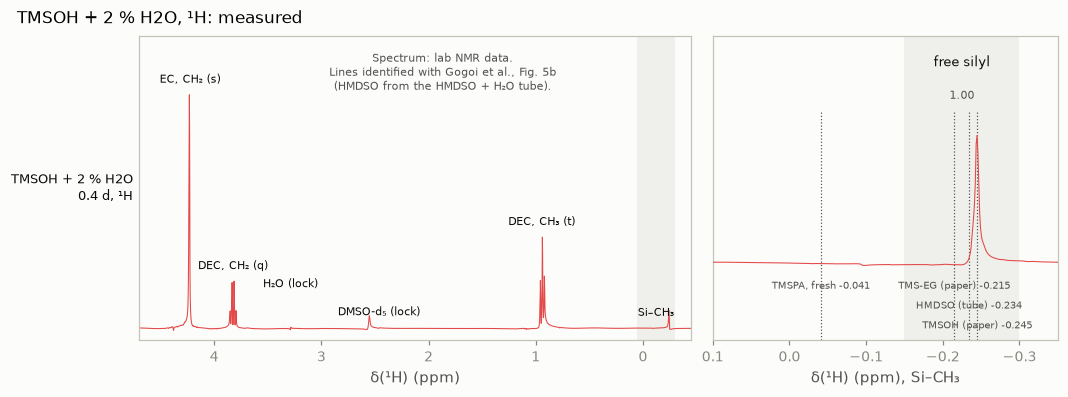

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-18 02:36:59,free silyl (silyl groups),449.6,0.0,0.0,3219,16,3.44,1,21.9


,,share,σ
,window,free silyl,free silyl
tube,days,,
TMSOH + 2 % H2O,0.39,1.000,0.000


In [6]:
show_folder('5v% TMSOH+2v% H2O in ECDEC')

### 1.5 `5v%TMSOTMS + 2v%H2O`

Not a fitted tube; no phosphate, so ¹H has only the window of the free silyl.

#### A. ²⁹Si

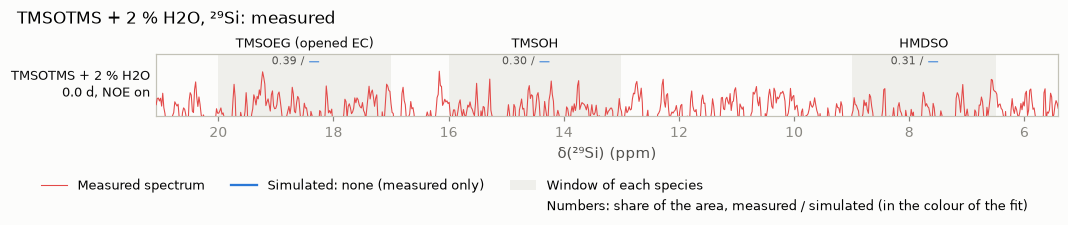

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-18 17:06:56,TMSOEG (silyl groups),181.5,26.6,14.6,3,6000,5.66,5,22.2


#### B. ¹H

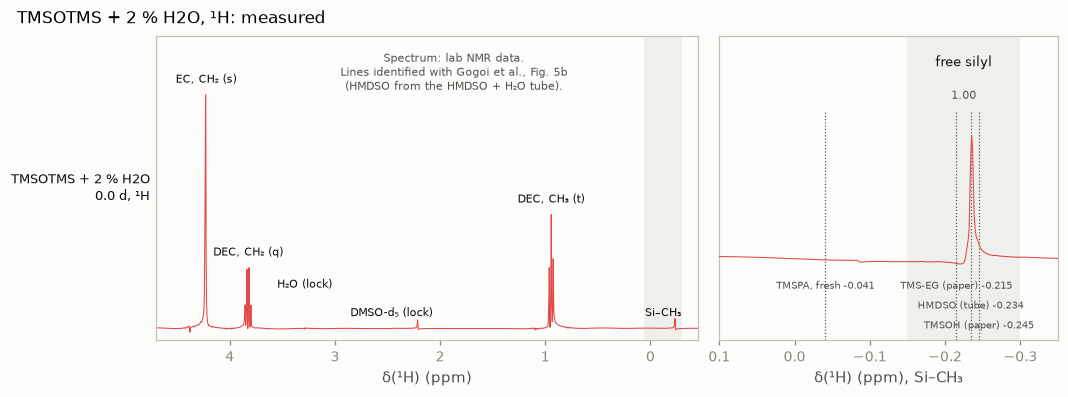

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-18 17:04:17,free silyl (silyl groups),470.5,0.0,0.0,2805,16,3.44,1,22.2


,,share,σ
,window,free silyl,free silyl
tube,days,,
TMSOTMS + 2 % H2O,0.00,1.000,0.000


In [7]:
show_folder('5v%TMSOTMS+2v%H2O in ECDEC')

---
## 2. Concentration plots

The five reaction experiments of §1 as concentrations in time, in the four panels of the C(t) figures of `05_fitting_rev08`. Only measured points: no model.

- **Point:** one window of one spectrum: its share × the amount all the windows of the nucleus count together at mixing (as the conc. column of §1), ± σ = √(σ_noise² + σ_baseline²). A window of one species gives that species (HMDSO in molecules); the windows of several (silyl on phosphate, P-bound and free silyl in ¹H) are in silyl groups, TMSOEG + TMSOdiEG together.
- **Shape:** the nucleus (● ³¹P, ◆ ¹³C, ▲ ²⁹Si, ■ ¹H). **Colour:** the species, as in NB05.
- **Noise:** a spectrum whose S/N (§1) is below `SN_RATIO` is not plotted; the cell prints which ones. A nucleus with one window only (¹H of the tubes without phosphate) is not plotted either: its share is 1 by construction.
- **Time:** hours since the first spectrum of the tube. Above the panels, when a spectrum was taken hot: the temperature of each spectrum.

In [8]:
# §2: the measured concentrations of a tube in the four panels of NB05 (demo.reactor_plots.CONCENTRATION_PANELS), no model
from demo.reactor_plots import CONCENTRATION_PANELS
from matplotlib.lines import Line2D

NUCLEUS_MARKERS = {'31P': 'o', '13C': 'D', '29Si': '^', '1H': 's'}
PANEL_OF_WINDOW = {'TMSPA': 0, 'BMSPA': 0, 'MMSPA': 0, 'H3PO4': 0, 'TMSOH': 1, 'HMDSO': 1, 'P-silyl': 1, 'P-bound silyl': 1,
                   'free silyl': 1, 'TMSOEG': 3}
GROUP_COLOURS = {'P-silyl': style.SERIES[6], 'P-bound silyl': style.SERIES[6], 'free silyl': style.SERIES[4], 'TMSOEG': fit_plots.INK_MUTED}
GROUP_LABELS = {'P-silyl': 'silyl on phosphate (silyl groups)', 'P-bound silyl': 'silyl on phosphate (silyl groups)',
                'free silyl': 'free silyl (silyl groups)', 'TMSOEG': 'TMSOEG + TMSOdiEG'}


def tabulate_concentrations(folders):
    # One row per window of every spectrum of the folders: concentration ± σ (mM), the spectrum's S/N, time and temperature
    files = list_folder(folders)
    shares, _ = tabulate_folder(files)
    rows = []
    for path, spectrum in shares.groupby('path', sort=False):
        tube, nucleus = spectrum['tube'].iloc[0], spectrum['nucleus'].iloc[0]
        members, c0 = SHARE_SPECIES[nucleus], mixing_c0(tube)
        total = sum(n * c0.get(sp, 0.0) for window in spectrum['window'] for sp, n in members[window].items())
        sn = signal_to_noise(path, nucleus, axis_offset(tube, nucleus))
        for _, r in spectrum.iterrows():
            species = members[r['window']]
            n = next(iter(species.values())) if len(species) == 1 else 1
            rows.append({'tube': tube, 'nucleus': nucleus, 'window': r['window'], 't_h': r['t_h'], 'T_C': r['T_C'], 'S/N': sn,
                         'windows': len(spectrum), 'conc_mM': 1000 * r['measured'] * total / n,
                         'sigma_mM': 1000 * np.hypot(r['sigma_noise'], r['sigma_baseline']) * total / n})
    return pd.DataFrame(rows)


def draw_concentrations(points, title):
    # The four panels of NB05 with the measured points only; a temperature strip above them if a spectrum was taken hot
    hot = (points['T_C'] >= RT_MAX_C).any()
    fig = plt.figure(figsize=(12, 8.4 if hot else 7.4), layout='constrained')
    grid = fig.add_gridspec(3 if hot else 2, 2, height_ratios=[0.4, 2, 2] if hot else [1, 1])
    axes = [fig.add_subplot(grid[(1 if hot else 0) + k // 2, k % 2]) for k in range(4)]
    span = max(float(points['t_h'].max() - min(points['t_h'].min(), 0.0)), 1.0)
    start, end = min(0.0, float(points['t_h'].min())) - 0.03 * span, float(points['t_h'].max()) + 0.03 * span
    if hot:
        spectra = points.drop_duplicates(['t_h', 'nucleus']).sort_values('t_h')
        for col in range(2):
            strip = fig.add_subplot(grid[0, col], sharex=axes[col])
            strip.plot(spectra['t_h'], spectra['T_C'], 'o', color=fit_plots.INK_MUTED, markersize=3.5)
            strip.set_ylabel('T (°C)')
            strip.tick_params(labelbottom=False)
    for k, (ax, (panel, species)) in enumerate(zip(axes, CONCENTRATION_PANELS)):
        mine = points[points['window'].map(PANEL_OF_WINDOW) == k]
        handles = {}
        for (window, nucleus), seen in mine.groupby(['window', 'nucleus'], sort=False):
            colour = GROUP_COLOURS[window] if window in GROUP_COLOURS else style.SERIES[species.index(window)]
            ax.errorbar(seen['t_h'], seen['conc_mM'], yerr=seen['sigma_mM'], fmt=NUCLEUS_MARKERS[nucleus], color=colour,
                        markersize=5.5, markeredgecolor=fit_plots.SURFACE, markeredgewidth=0.8, elinewidth=1.0, capsize=3, zorder=4)
            label = GROUP_LABELS.get(window, window)
            handles.setdefault(label, Line2D([], [], color=colour, marker='o', linestyle='none', markersize=6, label=label))
        if mine.empty:
            ax.set_yticks([])
            ax.text(0.5, 0.5, 'no NMR points', transform=ax.transAxes, ha='center', va='center', fontsize=9, color=fit_plots.INK_MUTED)
        else:
            low = float((mine['conc_mM'] - mine['sigma_mM']).min())
            ax.set_ylim(min(0.0, 1.08 * low), 1.08 * float((mine['conc_mM'] + mine['sigma_mM']).max()))
            ax.legend(handles=list(handles.values()), loc='best')
        ax.set_xlim(start, end)
        ax.set_title(panel, loc='left')
        ax.set_ylabel('Concentration (mM)')
        ax.set_xlabel('Time since the first spectrum of the tube (h)')
    shapes = [Line2D([], [], color=fit_plots.INK_MUTED, marker=m, linestyle='none', markersize=6, label=f'{fit_plots.NUCLEUS_LABELS[n]} (measured, ± σ)')
              for n, m in NUCLEUS_MARKERS.items() if n in set(points['nucleus'])]
    fig.legend(handles=shapes, loc='outside lower center', ncols=len(shapes))
    fig.suptitle(title, x=0.01, ha='left', fontsize=11)
    return fig


def show_concentrations(folders, sn_ratio):
    # A tube of §1: its points with S/N ≥ sn_ratio (the others printed as noise), in the four panels
    points = tabulate_concentrations(folders)
    noise = points[points['S/N'] < sn_ratio].drop_duplicates(['nucleus', 't_h'])
    for _, r in noise.iterrows():
        print(f"noise, not plotted: {fit_plots.NUCLEUS_LABELS[r['nucleus']]} at {r['t_h']:.1f} h, S/N {r['S/N']:.0f}")
    single = points[(points['windows'] == 1) & (points['S/N'] >= sn_ratio)].drop_duplicates(['nucleus', 't_h'])
    for _, r in single.iterrows():
        print(f"one window only, not plotted: {fit_plots.NUCLEUS_LABELS[r['nucleus']]} at {r['t_h']:.1f} h")
    shown = points[(points['S/N'] >= sn_ratio) & (points['windows'] > 1)]
    if shown.empty:
        print('nothing to plot above the noise limit')
        return
    fig = draw_concentrations(shown, f"{shown['tube'].iloc[0]}: measured concentrations (S/N ≥ {sn_ratio:g})")
    display(fig)
    plt.close(fig)

### 2.1 `5% TMSPa + 0.5v% H2O`

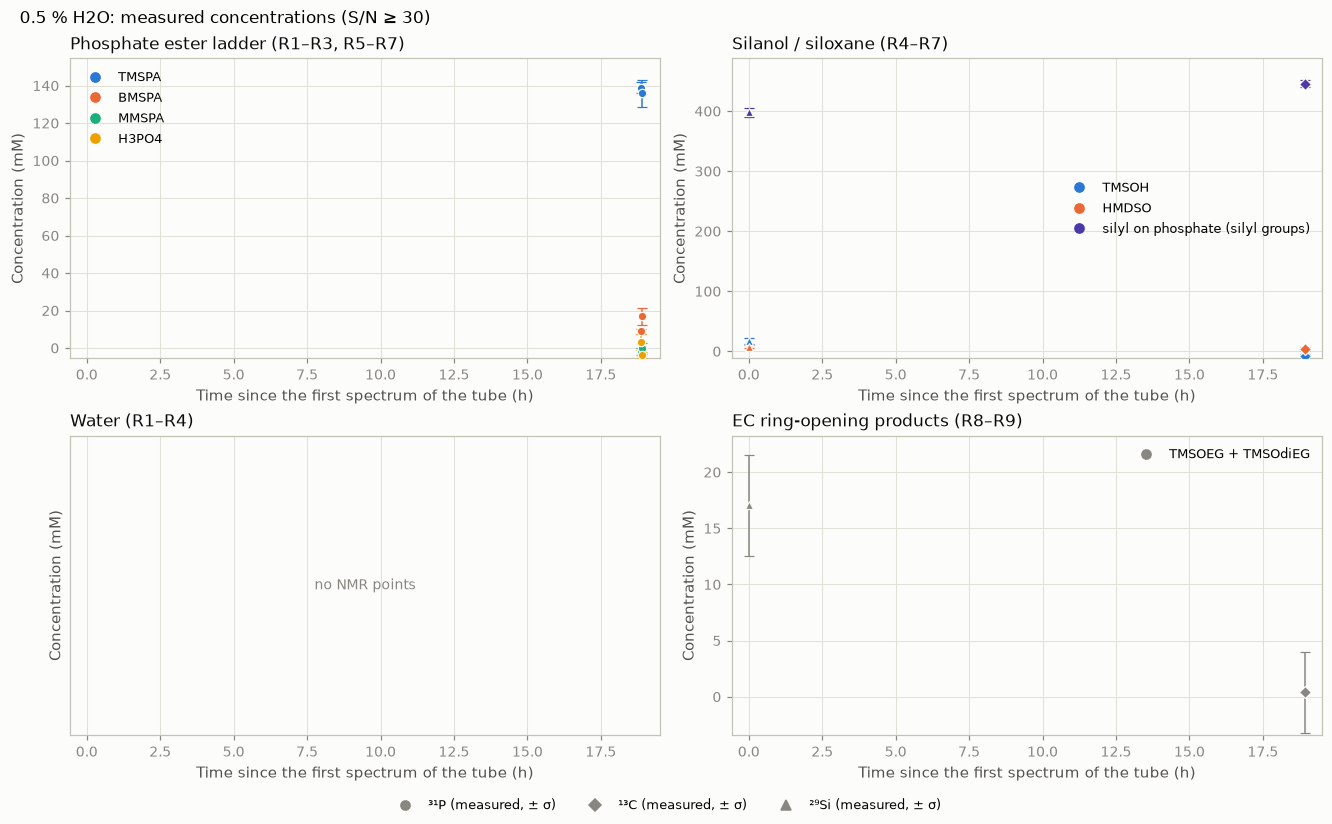

In [9]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations('5% TMSPa + 0.5v% H2O in EC-DEC', SN_RATIO)

### 2.2 `5% TMSPa + 2v% H2O`

noise, not plotted: ²⁹Si at 0.2 h, S/N 18
noise, not plotted: ²⁹Si at 33.6 h, S/N 24
noise, not plotted: ²⁹Si at 72.6 h, S/N 22
noise, not plotted: ²⁹Si at 96.6 h, S/N 24
noise, not plotted: ²⁹Si at 145.6 h, S/N 28


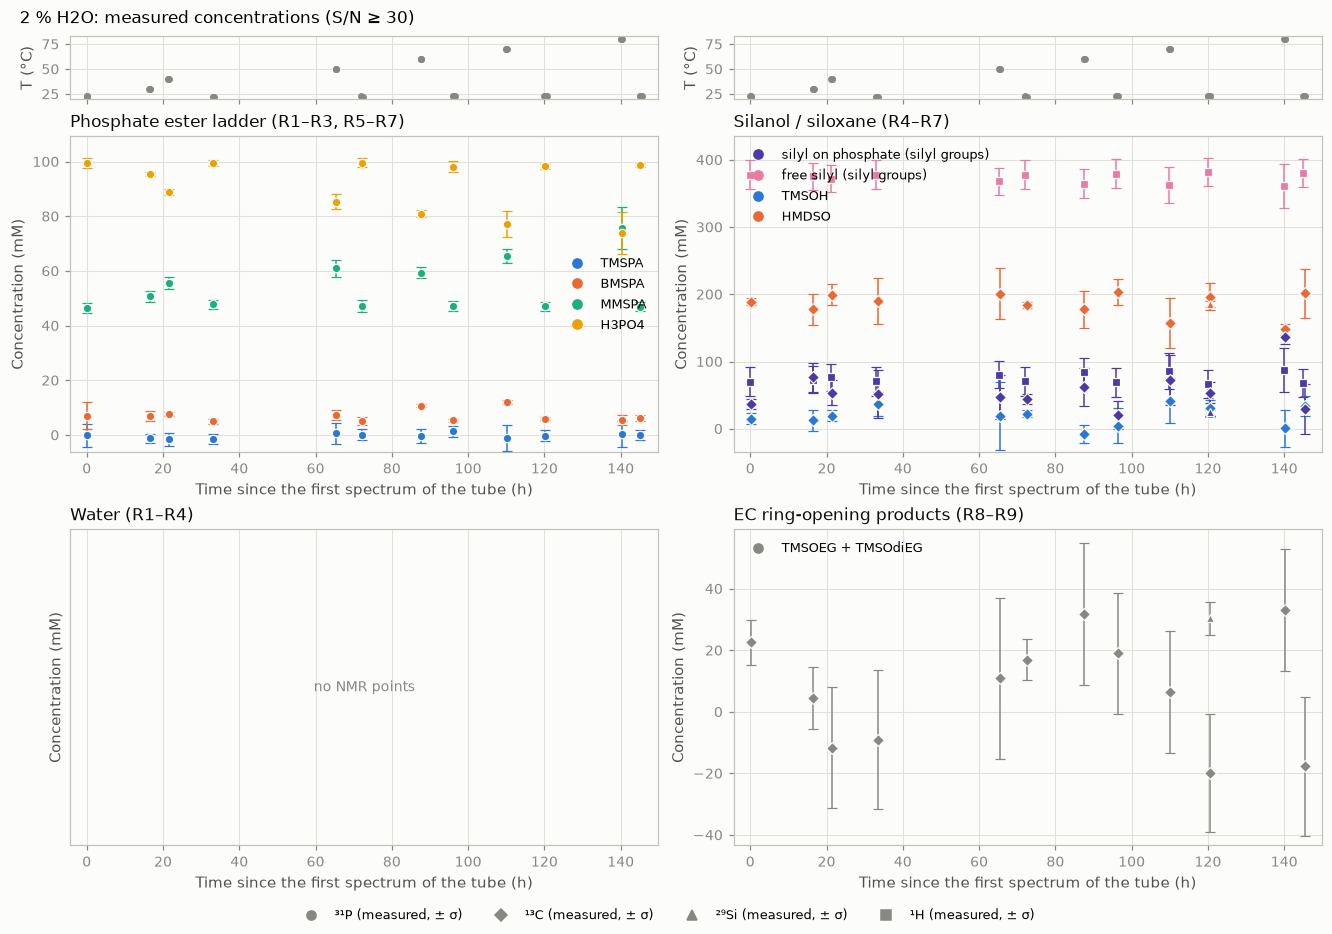

In [10]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations(['5% TMSPa + 2v% H2O in EC-DEC/Ramping Temperature', '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature'], SN_RATIO)

### 2.3 `5v%TMSPa + 2v%TMSOH`

noise, not plotted: ²⁹Si at 0.1 h, S/N 3


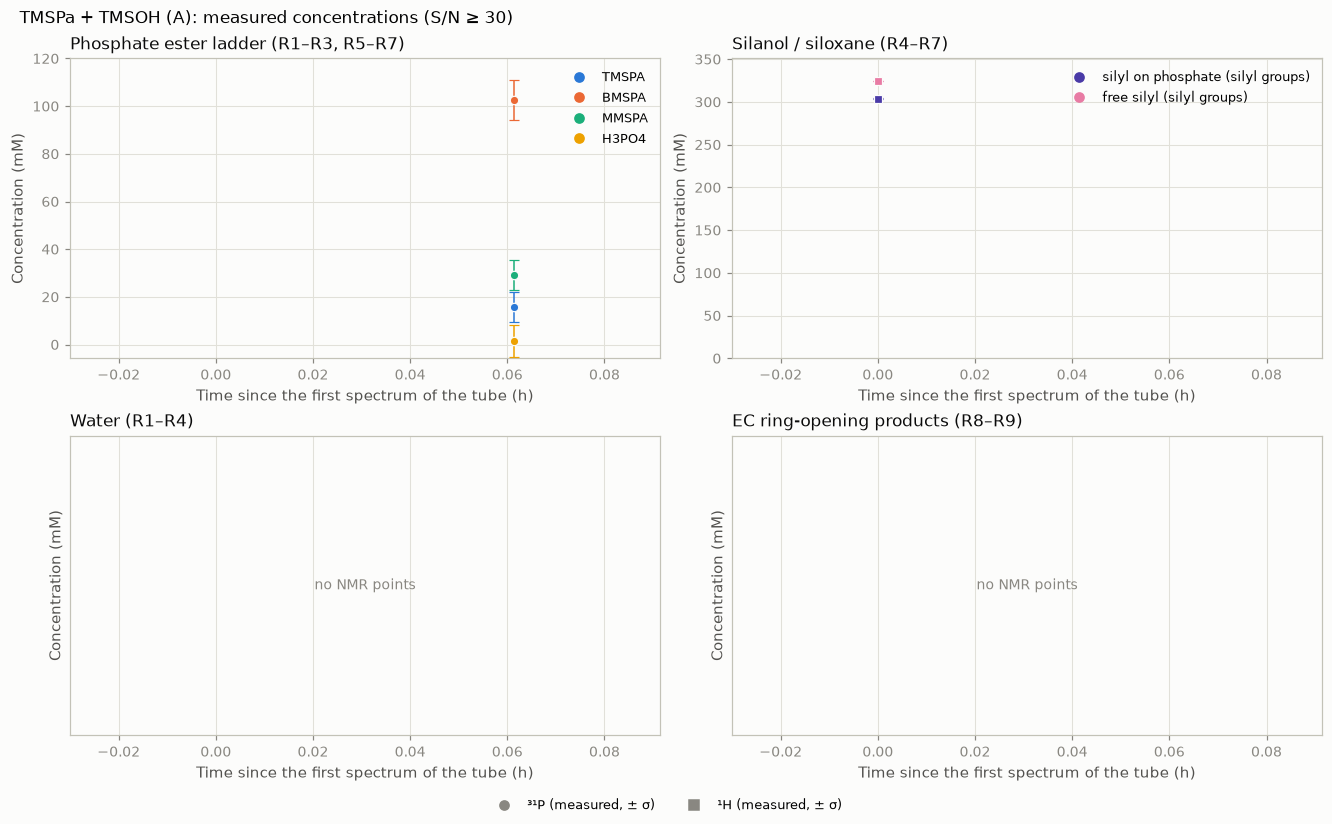

In [11]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations('5v%TMSPa+2v%TMSOH in ECDEC', SN_RATIO)

### 2.4 `5v% TMSOH + 2v% H2O`

In [12]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations('5v% TMSOH+2v% H2O in ECDEC', SN_RATIO)

noise, not plotted: ²⁹Si at 0.0 h, S/N 3
one window only, not plotted: ¹H at 9.4 h
nothing to plot above the noise limit


### 2.5 `5v%TMSOTMS + 2v%H2O`

In [13]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations('5v%TMSOTMS+2v%H2O in ECDEC', SN_RATIO)

noise, not plotted: ²⁹Si at 0.0 h, S/N 3
one window only, not plotted: ¹H at 0.0 h
nothing to plot above the noise limit


---
## 3. The 10-day experiments

Three folders of spectra taken on 25–26 May 2023, about ten days after the first spectra of each tube. Nothing is simulated: each figure shows the measured spectrum, the window of each species (grey) and its measured share of the area of the windows (²⁹Si: of the heights). Time: days since the first spectrum of the same tube.

- **Per nucleus (A, B, …):** as in §1: its figure, then its tables (files; measured shares ± σ).

### 3.1 `5v%TMSOTMS + 2v%H2O`, after 10 days

The folder holds the ¹H of two tubes, both without phosphate (title of each file): TMSOH + 2 % H₂O and TMSOTMS (HMDSO) + 2 % H₂O. Neither is a fitted tube. With no phosphate there is only the window of the free silyl, so its share is 1: what the figure shows is where the Si–CH₃ line sits against TMSOH and HMDSO.

#### A. ¹H

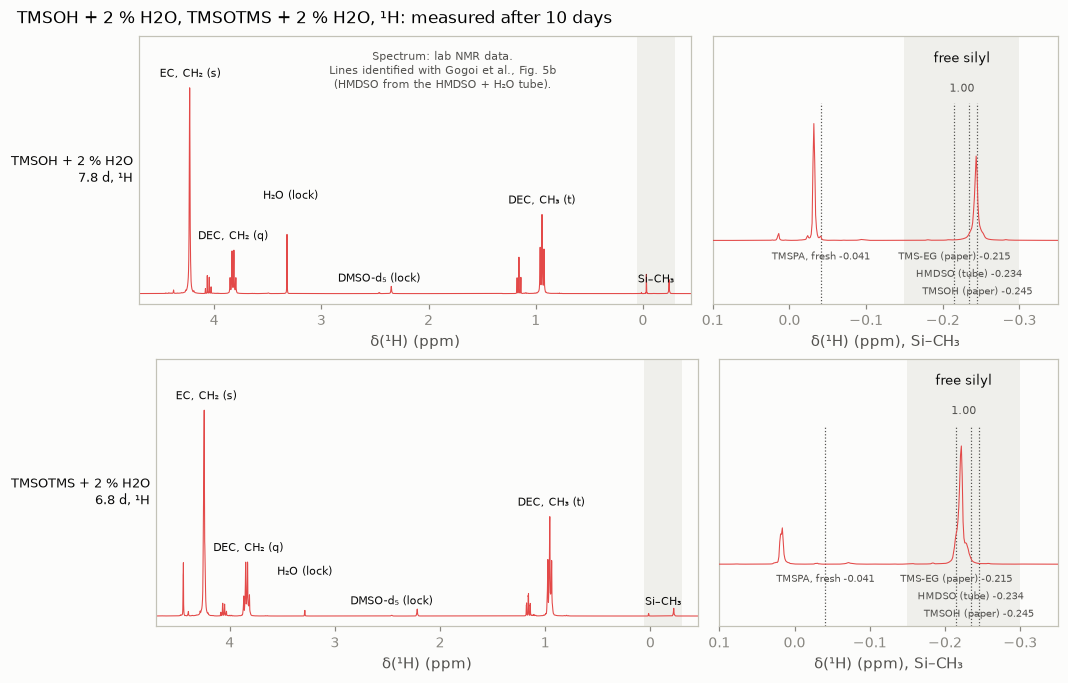

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-25 13:00:50,free silyl (silyl groups),449.6,0.0,0.0,3490,16,7.81,5,21.7
1H,2023-05-25 13:06:17,free silyl (silyl groups),470.5,0.0,0.0,2740,16,7.81,5,21.7


,,share,σ
,window,free silyl,free silyl
tube,days,,
TMSOH + 2 % H2O,7.83,1.000,0.000
TMSOTMS + 2 % H2O,6.83,1.000,0.000


In [14]:
show_folder('NG230525_5v%TMSOTMS+2v%H2O in EC_DEC_AFTER 10 DAYS', ' after 10 days')

### 3.2 `5v%TMSPa`, after 10 days

`TMSPa alone`: ³¹P and ¹H.

#### A. ³¹P

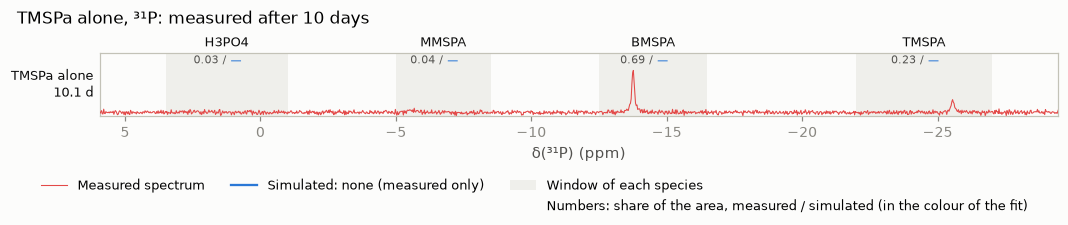

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2023-05-25 12:55:55,BMSPA,102.8,7.2,7.0,16,16,5.69,5,21.7


#### B. ¹H

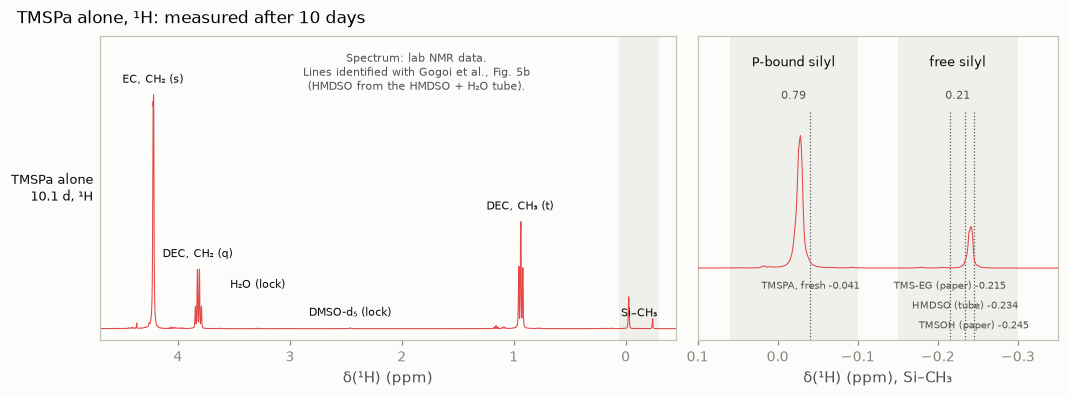

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-25 12:53:37,P-bound silyl (silyl groups),355.9,0.8,0.2,2859,16,7.81,5,21.7


In [15]:
show_folder('NG230525_5v%TMSPa in EC_DEC_AFTER 10 DAYS', ' after 10 days')

### 3.3 `5v%TMSPa + 2v%TMSOH`, after 10 days

`TMSPa + TMSOH (A)`: ¹³C and ¹H on 25 May; ¹H and ²⁹Si (INEPT) the next day, in files titled 5v% TMSPa + 5v% TMSOH.

#### A. ¹³C

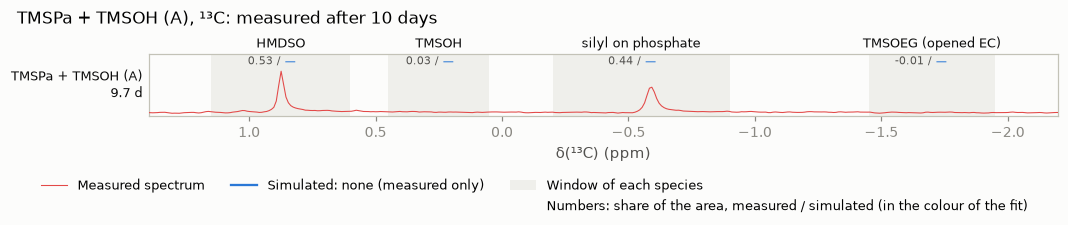

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
13C,2023-05-25 11:00:38,HMDSO,168.0,10.3,6.1,135,1024,3.06,2,21.7


#### B. ²⁹Si

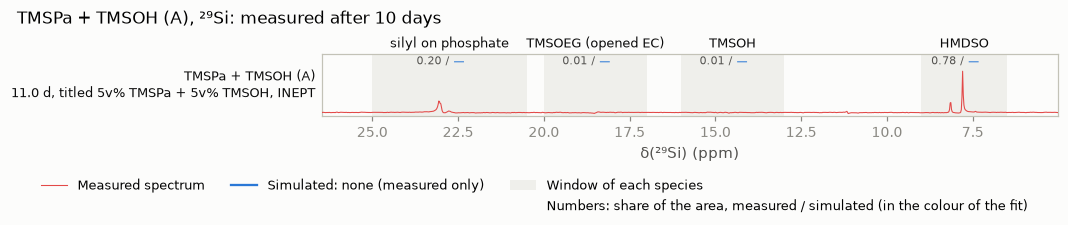

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-26 18:08:20,HMDSO,245.5,0.6,0.2,295,2500,2.76,2,21.8


#### C. ¹H

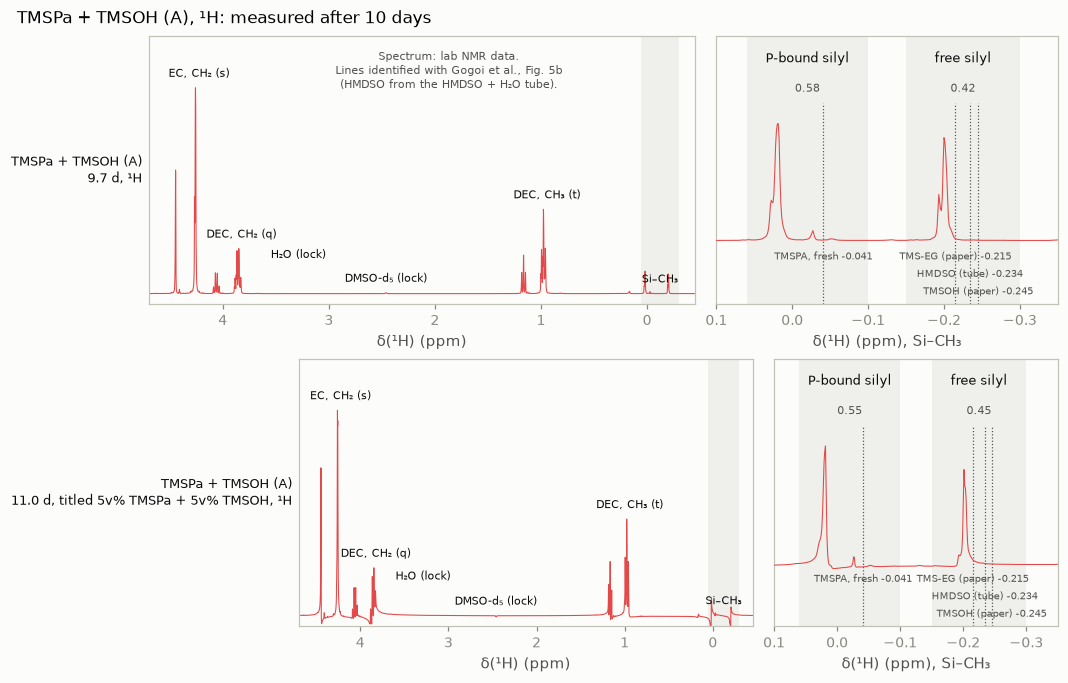

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-25 10:58:19,P-bound silyl (silyl groups),361.6,2.9,0.8,1497,16,7.81,5,21.9
1H,2023-05-26 18:04:54,P-bound silyl (silyl groups),345.6,3.9,1.1,1392,16,6.69,4,22.0


In [16]:
show_folder('NG230525_5v%TMSPa+2v%TMSOH in EC_DEC_AFTER 10 DAYS', ' after 10 days')